# Diamond Regression

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [84]:
df = pd.read_csv('diamonds.csv')
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [86]:
X = df[['carat', 'depth', 'table', 'x', 'y', 'z']]
y = df['price']

In [87]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[10686.31, -203.15, -102.45,-1315.67, 66.32, 41.63]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['carat','depth','table','x','y','z']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.085e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [88]:
print('Slope (m):', model.coef_)
print('Intercept (b):', model.intercept_)

Slope (m): [10686.30908063  -203.1540524   -102.44565213 -1315.6678418
    66.32160232    41.62769701]
Intercept (b): 20849.316413045766


- largest coefficient for `carat` suggests it has the largest impact on diamond pricing

In [89]:
from sklearn.metrics import mean_squared_error, r2_score
y_pred = model.predict(X)
y_pred

array([ 346.90971807,  -71.46876469,  126.3686742 , ..., 2503.1404693 ,
       4175.51576877, 3463.84440251], shape=(53940,))

In [90]:
print('MSE:', mean_squared_error(y,y_pred))
print('R2 Score:', r2_score(y,y_pred))

MSE: 2240581.7295427355
R2 Score: 0.8592186831580985


-  Finding the root of the MSE which is 1,496 suggests that the typical prediction error is around $1,496 for each diamond

- The R2 score of 0.86 tells us 86% of the price variation of the diamonds can be explained by our 6 features
    - so 14% of the price variation remains unexplained by our model

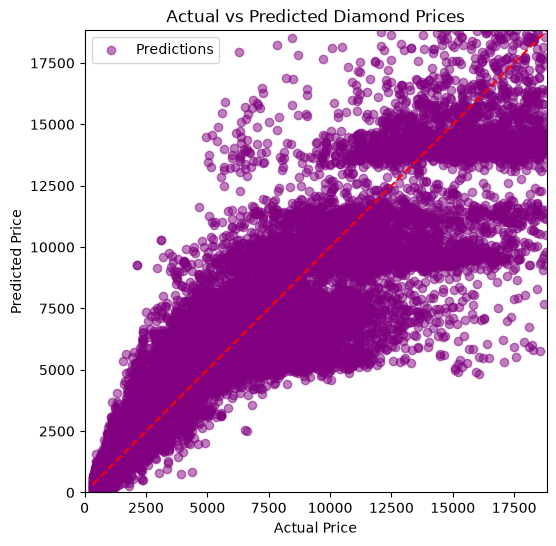

In [91]:
plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred, color='purple',alpha = 0.5, label='Predictions')

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color='red',
    linestyle='--'
)


plt.xlim(0, y.max())
plt.ylim(0, y.max())

plt.gca().set_aspect('equal', adjustable='box')


plt.title('Actual vs Predicted Diamond Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.legend()
plt.show()

#### Logistic regression

In [92]:
median_price = df['price'].median()
print(median_price)
df['Expensive'] = 0
df.loc[df['price'] > median_price, 'Expensive'] = 1
df.head()

2401.0


,carat,cut,color,clarity,depth,table,price,x,y,z,Expensive
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,0
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,0
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,0
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,0
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,0


In [93]:

df['Expensive'].value_counts()

Expensive
0    26985
1    26955
Name: count, dtype: int64

In [94]:
X = df[['carat', 'depth', 'table', 'x', 'y', 'z']]
y = df['Expensive']

In [95]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [96]:
df.sample()

,carat,cut,color,clarity,depth,table,price,x,y,z,Expensive
9008,1.01,Very Good,H,SI1,63.1,60.0,4513,6.41,6.37,4.03,1


In [97]:
model.predict_proba([[1.03,62.8,58.0,6.46,6.41,4.04]])

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[0.00312454, 0.99687546]])

In [98]:
from sklearn.metrics import accuracy_score,precision_score,recall_score
y_pred = model.predict(X)
y_pred


array([0, 0, 0, ..., 0, 1, 1], shape=(53940,))

In [99]:
print('Accuracy:', accuracy_score(y,y_pred))
print('Precision', precision_score(y,y_pred))
print('Recall:', recall_score(y,y_pred))

Accuracy: 0.9495736002966259
Precision 0.9402041631852364
Recall: 0.9601558152476349


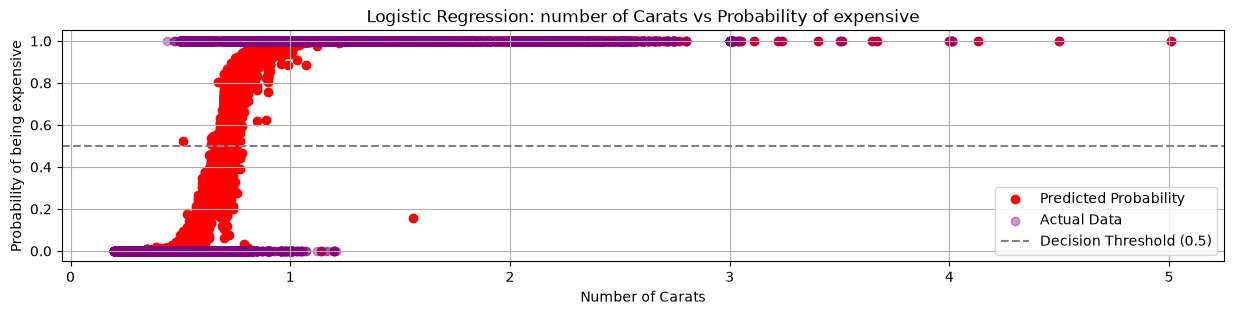

In [114]:
plt.figure(figsize=(15,3))
plt.scatter(
    df['carat'],
    model.predict_proba(X)[:, 1],
    color='red',
    label='Predicted Probability'
)

plt.scatter(df['carat'],y,color = 'purple',alpha=0.4, label='Actual Data')



plt.axhline(0.5, color='gray', linestyle='--', label = 'Decision Threshold (0.5)')

plt.title('Logistic Regression: number of Carats vs Probability of expensive')
plt.xlabel('Number of Carats')
plt.ylabel('Probability of being expensive')
plt.legend()
plt.grid(True)

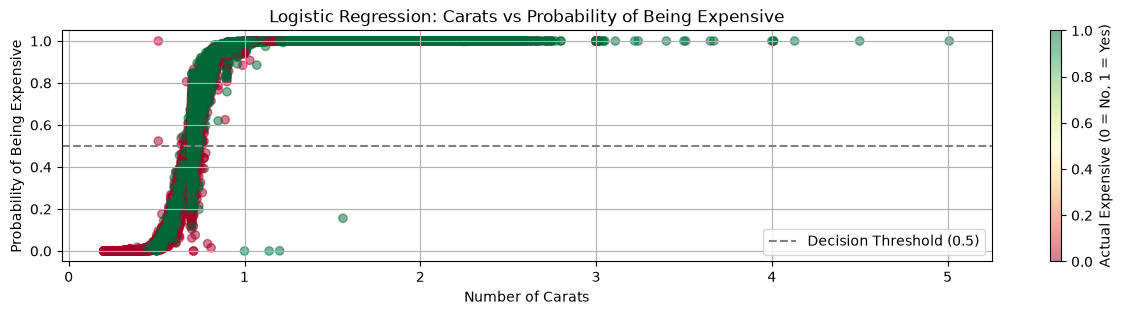

In [118]:
plt.figure(figsize=(15,3))

plt.scatter(
    df['carat'],
    model.predict_proba(X)[:, 1],
    c=df['Expensive'],
    cmap='RdYlGn',
    alpha=0.5
)

plt.axhline(0.5, color='gray', linestyle='--', label='Decision Threshold (0.5)')

plt.title('Logistic Regression: Carats vs Probability of Being Expensive')
plt.xlabel('Number of Carats')
plt.ylabel('Probability of Being Expensive')

plt.colorbar(label='Actual Expensive (0 = No, 1 = Yes)')
plt.legend()
plt.grid(True)
plt.show()

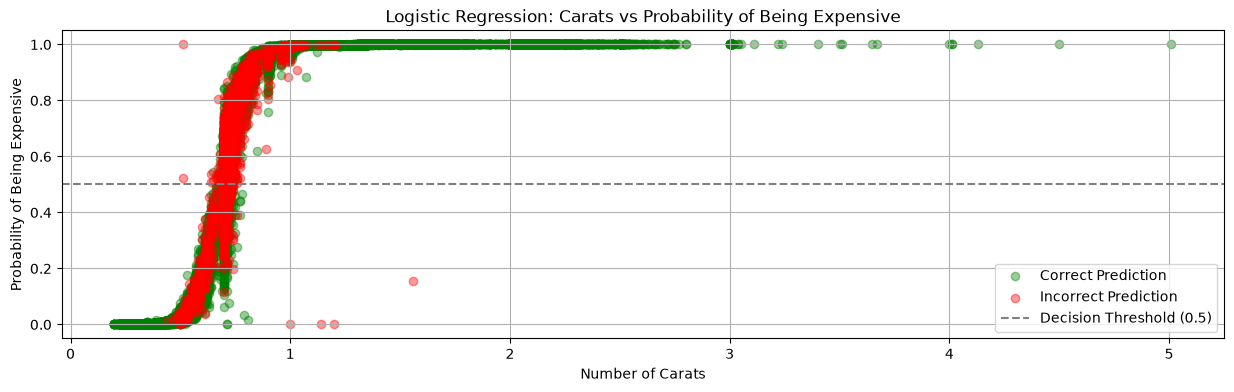

In [119]:
plt.figure(figsize=(15, 4))

probabilities = model.predict_proba(X)[:, 1]

# Correct if probability and actual classification agree
correct = ((probabilities >= 0.5) & (df['Expensive'] == 1)) | \
          ((probabilities < 0.5) & (df['Expensive'] == 0))

plt.scatter(
    df.loc[correct, 'carat'],
    probabilities[correct],
    color='green',
    alpha=0.4,
    label='Correct Prediction'
)

plt.scatter(
    df.loc[~correct, 'carat'],
    probabilities[~correct],
    color='red',
    alpha=0.4,
    label='Incorrect Prediction'
)

plt.axhline(0.5, color='gray', linestyle='--', label='Decision Threshold (0.5)')

plt.title('Logistic Regression: Carats vs Probability of Being Expensive')
plt.xlabel('Number of Carats')
plt.ylabel('Probability of Being Expensive')

plt.legend()
plt.grid(True)
plt.show()

In [121]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z,Expensive
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,0
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,0
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,0
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,0
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,0
...,...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50,1
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61,1
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56,1
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74,1


#### Reflection

1. I found Linear regression was  easier to understand as the predicted prices can be directly compared with actual values
2. Linear would be useful for pricing diamonds to sell them
    - Logistic would be useful for categorisig diamonds for insurance purposes such as high value or low value.
3. accuracy can be misleading as model is tested on data its already senn/ been trained on. It may struggle on new unseen data.
4. Yes they would matter as clarity and cut affects the price of a diamond. One-Hot encoding or Label-encoding can be used to convert text categories to binary to be used for modle training